# Data Preparation for Machine Learning

This notebook provides a step-by-step guide to cleaning tree data from Grenoble in order to predict the planting year.

## Objective
Prepare the data to train a Machine Learning model that can predict missing tree planting years.

## Notebook Outline
1. Import libraries and load data  
2. Initial data exploration  
3. Data cleaning  
4. Save the data as a pickle file

## 1. Importing Libraries and Loading Data

We use several essential Python libraries for data analysis:
- pandas: for data manipulation  
- numpy: for numerical computations  
- matplotlib and seaborn: for visualization  
- sklearn: for preparing data for Machine Learning

In [3]:
# Libraries
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [4]:
# Loading the Data
df = pd.read_csv('../arbres_grenoble_epsg4326.csv', sep=',', encoding='utf-8')

# Display the first few rows
print('Data preview:')
display(df.head())

# Dataset information
print('\nDataset information:')
display(df.info())

Data preview:


,elem_point_id,code,nom,genre,genre_desc,categorie,categorie_desc,sous_categorie,sous_categorie_desc,code_parent,...,diametrearbre,causeabattage,collectivite,stationmetro,hauteurarbre,portarbre,structure,forme,typenature,geo_point_2d
0,34835,ESP36318,AR36318,VEG,VEGETATION,ESP01,Arbre,ESP151,Arbre de voirie,ESP237,...,NaN,NaN,Grenoble Alpes Métropole,NaN,NaN,NaN,Métropole de Grenoble,NaN,NaN,"45.167098421885385,5.740131798404362"
1,34836,ESP36319,AR36319,VEG,VEGETATION,ESP01,Arbre,ESP151,Arbre de voirie,ESP237,...,NaN,NaN,Grenoble Alpes Métropole,NaN,NaN,NaN,Métropole de Grenoble,NaN,NaN,"45.16710682038838,5.740199792549315"
2,34837,ESP36320,AR36320,VEG,VEGETATION,ESP01,Arbre,ESP151,Arbre de voirie,ESP237,...,NaN,NaN,Grenoble Alpes Métropole,NaN,NaN,NaN,Métropole de Grenoble,NaN,NaN,"45.167115270975415,5.740265608803635"
3,34838,ESP36321,AR36321,VEG,VEGETATION,ESP01,Arbre,ESP151,Arbre de voirie,ESP237,...,NaN,NaN,Grenoble Alpes Métropole,NaN,NaN,NaN,Métropole de Grenoble,NaN,NaN,"45.16712715617142,5.740349032579623"
4,34839,ESP36322,AR36322,VEG,VEGETATION,ESP01,Arbre,ESP151,Arbre de voirie,ESP237,...,NaN,NaN,Grenoble Alpes Métropole,NaN,NaN,NaN,Métropole de Grenoble,NaN,NaN,"45.167144245872265,5.740471081600832"



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31670 entries, 0 to 31669
Data columns (total 38 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   elem_point_id          31670 non-null  int64  
 1   code                   31670 non-null  object 
 2   nom                    31670 non-null  object 
 3   genre                  31670 non-null  object 
 4   genre_desc             31670 non-null  object 
 5   categorie              31670 non-null  object 
 6   categorie_desc         31670 non-null  object 
 7   sous_categorie         31670 non-null  object 
 8   sous_categorie_desc    31670 non-null  object 
 9   code_parent            31670 non-null  object 
 10  code_parent_desc       31670 non-null  object 
 11  adr_secteur            31670 non-null  int64  
 12  bien_reference         31670 non-null  object 
 13  genre_bota             30859 non-null  object 
 14  espece                 29370 non

None

## 2. Initial Data Exploration

Before starting the cleaning process, it's crucial to understand our data:
- What columns are available?  
- What types of data do we have?  
- Are there any missing values?

In [21]:
# Descriptive Statistics

df.columns
df.dtypes

# Analysis of Missing Values

df.isna()
df.isna().sum()

elem_point_id                0
code                         0
nom                          0
genre                        0
genre_desc                   0
categorie                    0
categorie_desc               0
sous_categorie               0
sous_categorie_desc          0
code_parent                  0
code_parent_desc             0
adr_secteur                  0
bien_reference               0
genre_bota                 811
espece                    2300
variete                  27071
stadededeveloppement      4174
equipe                   31670
remarques                26358
anneedeplantation         2144
raisondeplantation       28383
traitementchenilles      29604
courrier                 31670
identifiantplu           31083
typeimplantationplu      26702
intituleprotectionplu    31083
anneeabattage            31670
essouchement             31670
diametrearbre            31670
causeabattage            31670
collectivite               718
stationmetro             29788
hauteura

In [22]:
df.columns

Index(['elem_point_id', 'code', 'nom', 'genre', 'genre_desc', 'categorie',
       'categorie_desc', 'sous_categorie', 'sous_categorie_desc',
       'code_parent', 'code_parent_desc', 'adr_secteur', 'bien_reference',
       'genre_bota', 'espece', 'variete', 'stadededeveloppement', 'equipe',
       'remarques', 'anneedeplantation', 'raisondeplantation',
       'traitementchenilles', 'courrier', 'identifiantplu',
       'typeimplantationplu', 'intituleprotectionplu', 'anneeabattage',
       'essouchement', 'diametrearbre', 'causeabattage', 'collectivite',
       'stationmetro', 'hauteurarbre', 'portarbre', 'structure', 'forme',
       'typenature', 'geo_point_2d'],
      dtype='object')

### Visualisation of missing values

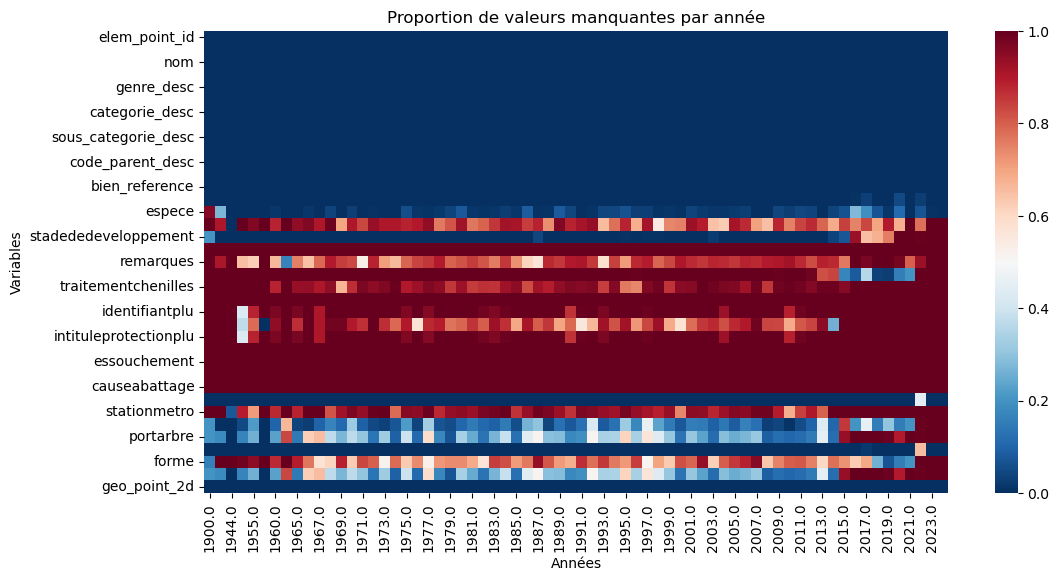

In [26]:
# Creation of a heatmap to visualize missing values
import seaborn as sns
import matplotlib.pyplot as plt
columns = df.columns
df_missing= df.copy()

# Proportion de valeurs manquantes par année et par variable
df_missing = df.groupby('anneedeplantation').apply(
    lambda groupe: groupe.isna().mean(),
    include_groups=False
)

# Inverser lignes et colonnes
df_missing = df_missing.T

plt.figure(figsize=(12, 6))

sns.heatmap(
    df_missing,
    cmap="RdBu_r",
    vmin=0,
    vmax=1,
    annot=False,
)

plt.xlabel("Années")
plt.ylabel("Variables")
plt.title("Proportion de valeurs manquantes par année")

plt.show()



## 3. Data Cleaning

### 3.1 After the initial analysis, we will:
1. Remove rows without a planting year **'annedeplantation'**
2. Drop columns that are irrelevant for prediction  
3. Extract geographic coordinates

In [29]:
# 1. Remove rows without a planting year **'annedeplantation'**
df = df.dropna(subset=['anneedeplantation'])

### 🔍 3.2 Cleaning Unnecessary Columns

We will:

- Remove columns with more than **40% missing values**  
- Remove columns that are **too specific** (e.g., unique identifiers), which don't provide useful information for machine learning  
- Remove columns that contain redundant or unhelpful information

In [32]:
df.columns

Index(['elem_point_id', 'code', 'nom', 'genre', 'genre_desc', 'categorie',
       'categorie_desc', 'sous_categorie', 'sous_categorie_desc',
       'code_parent', 'code_parent_desc', 'adr_secteur', 'bien_reference',
       'genre_bota', 'espece', 'variete', 'stadededeveloppement', 'equipe',
       'remarques', 'anneedeplantation', 'raisondeplantation',
       'traitementchenilles', 'courrier', 'identifiantplu',
       'typeimplantationplu', 'intituleprotectionplu', 'anneeabattage',
       'essouchement', 'diametrearbre', 'causeabattage', 'collectivite',
       'stationmetro', 'hauteurarbre', 'portarbre', 'structure', 'forme',
       'typenature', 'geo_point_2d'],
      dtype='object')

In [37]:
# 2 Remove overly specific columns, such as the 'elem_point_id' column
df = df.drop(columns = ['elem_point_id'])

In [ ]:
# 3. Extract geographic coordinates

## 4. Save to data to a pickle file

In [ ]:
# Save to data to a pickle file

## Conclusion

We have completed several important cleaning steps:
1. Removed irrelevant columns or those with too many missing values  
2. Extracted geographic coordinates  

The data is now ready for the next steps of the project.